In [1]:
import pandas as pd

In [2]:
df = pd.read_csv("online_learning_course_consumption_dataset.csv")
df.head()

,User_ID,Experience_Level,Course_Type,Platform,Hours_Spent_Per_Week,Course_Duration_Weeks,Completion_Status,Completion_Percentage,Dropout_Reason,Satisfaction_Score
0,U0001,Fresher,Tech,Skillshare,16,8,Completed,67,No Dropout,2
1,U0002,Fresher,Non-Tech,edX,17,22,Dropped,38,Time Constraint,3
2,U0003,Fresher,Non-Tech,Coursera,19,21,In Progress,43,No Dropout,1
3,U0004,Student,Non-Tech,Udemy,14,2,Dropped,14,Time Constraint,1
4,U0005,Student,Non-Tech,Skillshare,8,10,Dropped,8,Too Difficult,4


In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 500 entries, 0 to 499
Data columns (total 10 columns):
 #   Column                 Non-Null Count  Dtype 
---  ------                 --------------  ----- 
 0   User_ID                500 non-null    object
 1   Experience_Level       500 non-null    object
 2   Course_Type            500 non-null    object
 3   Platform               500 non-null    object
 4   Hours_Spent_Per_Week   500 non-null    int64 
 5   Course_Duration_Weeks  500 non-null    int64 
 6   Completion_Status      500 non-null    object
 7   Completion_Percentage  500 non-null    int64 
 8   Dropout_Reason         500 non-null    object
 9   Satisfaction_Score     500 non-null    int64 
dtypes: int64(4), object(6)
memory usage: 39.2+ KB


In [4]:
df.shape 

(500, 10)

In [5]:
df.columns 

Index(['User_ID', 'Experience_Level', 'Course_Type', 'Platform',
       'Hours_Spent_Per_Week', 'Course_Duration_Weeks', 'Completion_Status',
       'Completion_Percentage', 'Dropout_Reason', 'Satisfaction_Score'],
      dtype='object')

In [6]:
# 1. Create the churn label
df['Churn'] = df['Completion_Status'].apply(lambda x: 1 if x == 'Dropped' else 0)

# 2. Select features (drop ID, drop target-leaking column, drop original status)
features = df.drop(columns=['User_ID', 'Completion_Status', 'Dropout_Reason', 'Churn'])
target = df['Churn']

# 3. Encode categorical columns
features_encoded = pd.get_dummies(features, columns=['Experience_Level', 'Course_Type', 'Platform'], drop_first=True)

features_encoded.head()

,Hours_Spent_Per_Week,Course_Duration_Weeks,Completion_Percentage,Satisfaction_Score,Experience_Level_Student,Experience_Level_Working Professional,Course_Type_Tech,Platform_Skillshare,Platform_Udemy,Platform_YouTube,Platform_edX
0,16,8,67,2,False,False,True,True,False,False,False
1,17,22,38,3,False,False,False,False,False,False,True
2,19,21,43,1,False,False,False,False,False,False,False
3,14,2,14,1,True,False,False,False,True,False,False
4,8,10,8,4,True,False,False,True,False,False,False


In [9]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    features_encoded, target, test_size=0.2, random_state=42, stratify=target
)
from sklearn.ensemble import RandomForestClassifier

rf_model = RandomForestClassifier(n_estimators=100, random_state=42)
rf_model.fit(X_train, y_train)

RandomForestClassifier(random_state=42)

In [10]:
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score

y_pred = rf_model.predict(X_test)

print("Accuracy:", accuracy_score(y_test, y_pred))
print("\nClassification Report:\n", classification_report(y_test, y_pred))
print("\nConfusion Matrix:\n", confusion_matrix(y_test, y_pred))

Accuracy: 0.92

Classification Report:
               precision    recall  f1-score   support

           0       0.98      0.89      0.94        65
           1       0.83      0.97      0.89        35

    accuracy                           0.92       100
   macro avg       0.91      0.93      0.92       100
weighted avg       0.93      0.92      0.92       100


Confusion Matrix:
 [[58  7]
 [ 1 34]]


In [11]:
import pandas as pd

importances = pd.Series(rf_model.feature_importances_, index=X_train.columns)
importances.sort_values(ascending=False)

Completion_Percentage                    0.686215
Course_Duration_Weeks                    0.092030
Hours_Spent_Per_Week                     0.084100
Satisfaction_Score                       0.045479
Course_Type_Tech                         0.016457
Experience_Level_Working Professional    0.016030
Experience_Level_Student                 0.015985
Platform_edX                             0.011641
Platform_Udemy                           0.011003
Platform_YouTube                         0.010617
Platform_Skillshare                      0.010443
dtype: float64

In [12]:
from sklearn.ensemble import GradientBoostingClassifier

gb_model = GradientBoostingClassifier(random_state=42)
gb_model.fit(X_train, y_train)
y_pred_gb = gb_model.predict(X_test)

print("Accuracy:", accuracy_score(y_test, y_pred_gb))
print(classification_report(y_test, y_pred_gb))

Accuracy: 0.92
              precision    recall  f1-score   support

           0       0.94      0.94      0.94        65
           1       0.89      0.89      0.89        35

    accuracy                           0.92       100
   macro avg       0.91      0.91      0.91       100
weighted avg       0.92      0.92      0.92       100



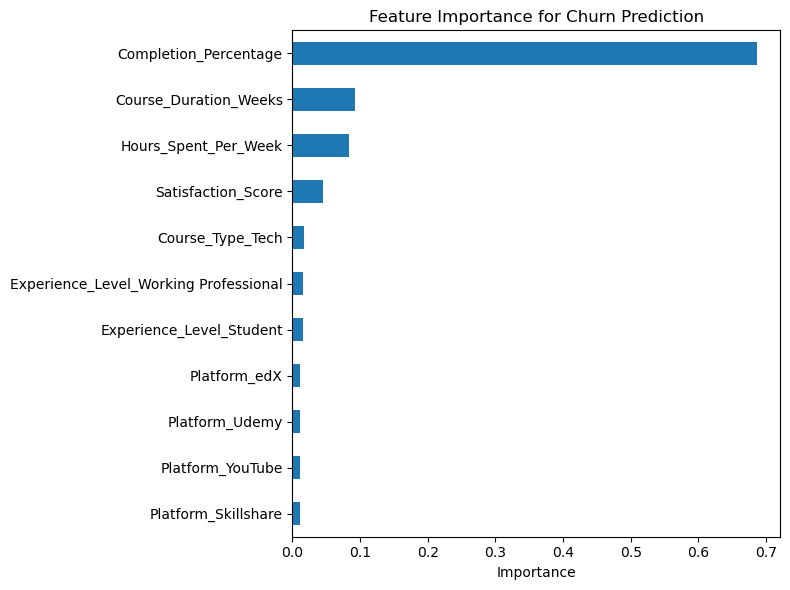

In [13]:
import matplotlib.pyplot as plt

importances.sort_values().plot(kind='barh', figsize=(8,6))
plt.title("Feature Importance for Churn Prediction")
plt.xlabel("Importance")
plt.tight_layout()
plt.show()

In [14]:
import pandas as pd
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

# Predictions from both models (assuming both are already trained)
y_pred_rf = rf_model.predict(X_test)
y_pred_gb = gb_model.predict(X_test)

comparison = pd.DataFrame({
    "Model": ["Random Forest", "Gradient Boosting"],
    "Accuracy": [accuracy_score(y_test, y_pred_rf), accuracy_score(y_test, y_pred_gb)],
    "Precision (Churn)": [precision_score(y_test, y_pred_rf), precision_score(y_test, y_pred_gb)],
    "Recall (Churn)": [recall_score(y_test, y_pred_rf), recall_score(y_test, y_pred_gb)],
    "F1-score (Churn)": [f1_score(y_test, y_pred_rf), f1_score(y_test, y_pred_gb)]
})

comparison

,Model,Accuracy,Precision (Churn),Recall (Churn),F1-score (Churn)
0,Random Forest,0.92,0.829268,0.971429,0.894737
1,Gradient Boosting,0.92,0.885714,0.885714,0.885714


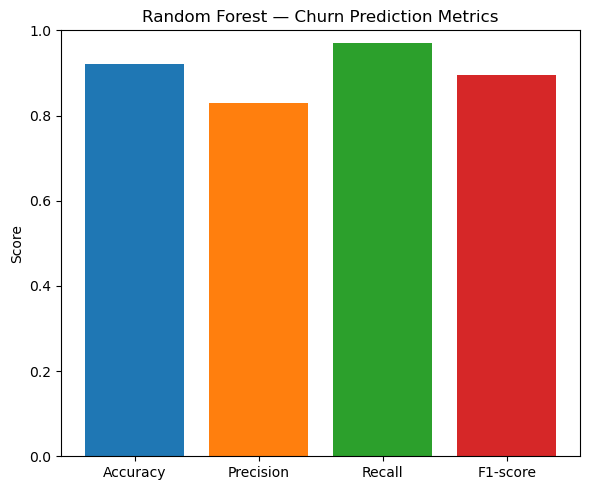

In [16]:
plt.figure(figsize=(6,5))
plt.bar(
    ["Accuracy", "Precision", "Recall", "F1-score"],
    [accuracy_score(y_test, y_pred_rf),
     precision_score(y_test, y_pred_rf),
     recall_score(y_test, y_pred_rf),
     f1_score(y_test, y_pred_rf)],
    color=["#1f77b4", "#ff7f0e", "#2ca02c", "#d62728"]
)
plt.title("Random Forest — Churn Prediction Metrics")
plt.ylabel("Score")
plt.ylim(0, 1)
plt.tight_layout()
plt.show()

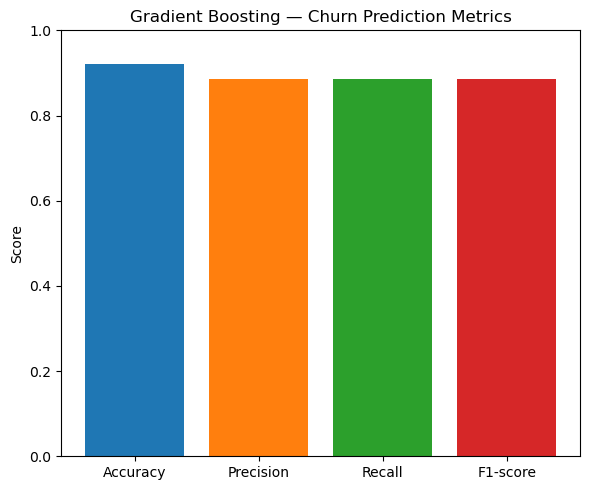

In [17]:
plt.figure(figsize=(6,5))
plt.bar(
    ["Accuracy", "Precision", "Recall", "F1-score"],
    [accuracy_score(y_test, y_pred_gb),
     precision_score(y_test, y_pred_gb),
     recall_score(y_test, y_pred_gb),
     f1_score(y_test, y_pred_gb)],
    color=["#1f77b4", "#ff7f0e", "#2ca02c", "#d62728"]
)
plt.title("Gradient Boosting — Churn Prediction Metrics")
plt.ylabel("Score")
plt.ylim(0, 1)
plt.tight_layout()
plt.show()

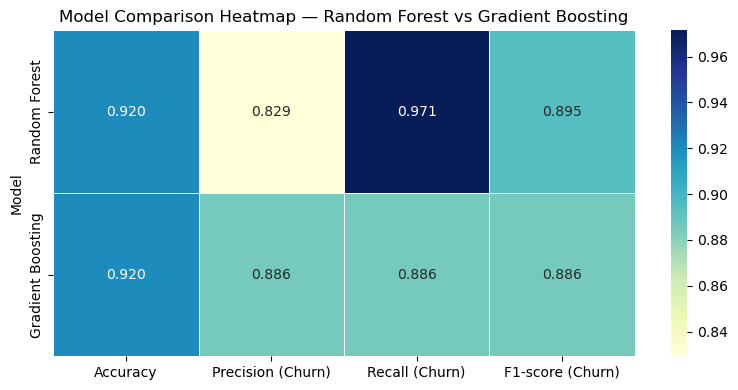

In [18]:
import seaborn as sns

comparison_metrics = comparison.set_index("Model")[["Accuracy", "Precision (Churn)", "Recall (Churn)", "F1-score (Churn)"]]

plt.figure(figsize=(8, 4))
sns.heatmap(comparison_metrics, annot=True, fmt=".3f", cmap="YlGnBu", cbar=True, linewidths=0.5)
plt.title("Model Comparison Heatmap — Random Forest vs Gradient Boosting")
plt.tight_layout()
plt.show()

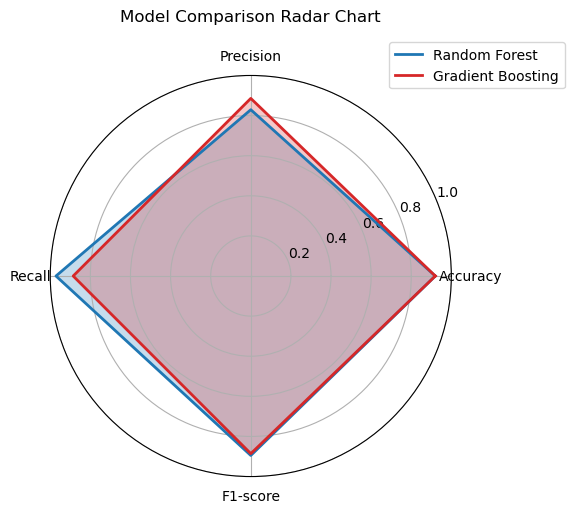

In [19]:
import numpy as np

metrics = ["Accuracy", "Precision", "Recall", "F1-score"]
rf_scores = [accuracy_score(y_test, y_pred_rf), precision_score(y_test, y_pred_rf),
             recall_score(y_test, y_pred_rf), f1_score(y_test, y_pred_rf)]
gb_scores = [accuracy_score(y_test, y_pred_gb), precision_score(y_test, y_pred_gb),
             recall_score(y_test, y_pred_gb), f1_score(y_test, y_pred_gb)]

# Close the loop for the radar shape
angles = np.linspace(0, 2 * np.pi, len(metrics), endpoint=False).tolist()
rf_scores += rf_scores[:1]
gb_scores += gb_scores[:1]
angles += angles[:1]

fig, ax = plt.subplots(figsize=(6, 6), subplot_kw=dict(polar=True))

ax.plot(angles, rf_scores, color="#1f77b4", linewidth=2, label="Random Forest")
ax.fill(angles, rf_scores, color="#1f77b4", alpha=0.25)

ax.plot(angles, gb_scores, color="#d62728", linewidth=2, label="Gradient Boosting")
ax.fill(angles, gb_scores, color="#d62728", alpha=0.25)

ax.set_xticks(angles[:-1])
ax.set_xticklabels(metrics)
ax.set_ylim(0, 1)
ax.set_title("Model Comparison Radar Chart", pad=20)
ax.legend(loc="upper right", bbox_to_anchor=(1.3, 1.1))

plt.tight_layout()
plt.show()

## Churn Prediction Model — Summary

### Objective
Predict which users are likely to leave (churn from) the online learning platform, using engagement behavior data, so that at-risk users can be identified early and offered personalized support.

### Data
A dataset of 500 users (`online_learning_course_consumption_dataset.csv`) containing engagement and course-related attributes: hours spent per week, course duration, completion percentage, satisfaction score, experience level, course type, and platform.

### Approach
- Defined the churn label from `Completion_Status`: users marked **Dropped** were labeled as churned (1), all others as not churned (0).
- Excluded `User_ID` (identifier, no predictive value) and `Dropout_Reason` (a consequence of churn, not a predictive signal — including it would leak the outcome).
- Encoded categorical features (`Experience_Level`, `Course_Type`, `Platform`) using one-hot encoding.
- Split data into 80% training / 20% testing sets, with stratification to preserve the churn ratio.

### Models Compared
Two models were trained and evaluated, as required by the task:

| Metric | Random Forest | Gradient Boosting |
|---|---|---|
| Accuracy | 0.92 | 0.92 |
| Precision (Churn) | 0.83 | 0.89 |
| Recall (Churn) | **0.97** | 0.89 |
| F1-score (Churn) | 0.89 | 0.89 |

Both models were also compared visually using a heatmap and a radar chart to examine trade-offs across all four metrics.

### Key Insight
`Completion_Percentage` was by far the most important predictor of churn (68.6% feature importance) — far ahead of course duration, weekly hours, and satisfaction score. This suggests that **early drop in course progress is the clearest warning sign of churn**, more so than how satisfied a user reports being.

### Final Model Choice
**Random Forest** was selected as the final model. While both models tied on accuracy and F1-score, Random Forest achieved substantially higher recall (97% vs. 89%) on churned users — meaning it missed far fewer at-risk students. In a churn-prevention context, the cost of missing a real churner outweighs the cost of a false alarm, making recall the more important metric to optimize.

### Recommendation
The platform should monitor `Completion_Percentage` as an early-warning signal and trigger personalized support (reminders, check-ins, simplified content) as soon as a user's progress stalls significantly below expected pace — rather than waiting for satisfaction scores or inactivity to signal risk.